<div style="box-sizing:border-box;max-width:100%;margin:0 0 8px;padding:4px 0;color:inherit;line-height:1.35;"><img src="https://thetahat.ru/images/logo_thetahat.png" alt="ThetaHat" style="display:block!important;width:52px!important;max-width:52px!important;height:auto!important;margin:0 0 9px 0!important;padding:0!important;"><div style="display:flex;align-items:center;justify-content:space-between;flex-wrap:wrap;gap:8px 12px;"><span style="min-width:0;color:inherit;font-size:12px;font-weight:700;letter-spacing:0.055em;text-transform:uppercase;"><a href="https://thetahat.ru/courses/ysda-group" style="color:inherit;text-decoration:none;">Школа анализа данных</a>&nbsp;·&nbsp;Машинное обучение</span></div></div>

<h2><span style="display:block;box-sizing:border-box;max-width:100%;padding:16px 22px 17px;border-radius:14px;background:linear-gradient(135deg,#D4470E 0%,#C7324E 50%,#B316B8 100%);color:#FFFFFF;line-height:1.15;font-weight:500;">Домашнее задание 4. Регуляризация.</span></h2>

<div style="box-sizing:border-box;max-width:100%;margin:18px 0 26px;padding:18px 20px;border:1px solid rgba(127, 127, 127, 0.28);border-left:4px solid #F13A3F;border-radius:12px;background:rgba(127, 127, 127, 0.07);color:inherit;">
  <div style="color:inherit;font-size:12px;font-weight:800;letter-spacing:0.08em;text-transform:uppercase;">Общие правила</div>
  <ul style="margin:10px 0 0;padding-left:22px;line-height:1.55;">
    <li>Выполненную работу <strong>в формате <code>ipynb</code></strong> нужно отправить в кабинете студента <a href="https://thetahat.ru/"><strong>на сайте ThetaHat</strong></a>. Инструкция по регистрации на сайте, записи на курс и сдаче домашек есть на странице курса в ЛМС. <strong>Работы, присланные иным способом, не принимаются.</strong> Дедлайны указаны в личном кабинете, они являются строгими.</li>
    <li>Обязательно изучите <a href="https://thetahat.ru/courses/design-hw"><strong>руководство по оформлению ДЗ</strong></a>. В частности, оно содержит примеры случаев, когда могут быть снижены баллы.</li>
    <li>Обратите внимание на <a href="https://thetahat.ru/courses/ai-rules"><strong>правила использования ИИ-инструментов</strong></a> при решении домашнего задания.</li>
    <li>Выполнять задание необходимо полностью самостоятельно. <strong>При обнаружении списывания (в т.ч. злоупотребление ИИ) всем участникам списывания дается штраф согласно правилам на странице курса.</strong></li>
    <li>Решение проверяется системой ИИ-проверки <a href="https://thetahat.ru/thetagrader"><img src="https://thetahat.ru/images/ai_eval_small.png" style="display:inline;vertical-align:middle;" alt="ThetaGrader"></a> <a href="https://thetahat.ru/thetagrader"><strong>ThetaGrader</strong></a>. Результаты проверки будут отправлены вам в течение 1-2 суток после дедлайна. После вы можете исправить ошибки или аргументировать свое мнение и отправить на проверку проверяющему. Подробнее на странице курса в ЛМС.</li>
    <li>Никакой код из данного задания при проверке запускаться не будет. <em>Если код не выполнен, недописан и т.д., то он не оценивается.</em></li>
  </ul>
  </br>
    
  <div style="color:inherit;font-size:12px;font-weight:800;letter-spacing:0.08em;text-transform:uppercase;">Правила заполнения ноутбука</div>
  <ul style="margin:8px 0 0;padding-left:22px;line-height:1.55;">
    <li>Запрещается удалять имеющиеся в ноутбуке ячейки, менять местами положения существующих ячеек.</li>
    <li>Отвечайте на вопросы, а также добавляйте новые ячейки в любом количестве в предложенных местах, которые обозначены <code>&lt;...&gt;</code>.</li>
    <li>Сохраняйте естественный линейный порядок повествования в ноутбуке сверху-вниз. Комментарии к решению пишите в markdown-ячейках. Выполнение задания (ход решения, выводы и пр.) должно быть осуществлено на русском языке.</li>
    <li>В markdown-ячейках, содержащих описание задачи, находятся специальные отметки, которые <strong style="color:red;">запрещается модифицировать</strong>.</li>
    <li>Решение теоретических задач оформляйте в markdown-ячейках в формате $\LaTeX$. При решении можно использовать ИИ-инструменты для оформления написанного самостоятельно решения, например, написать черновик формул и попросить ИИ оформить эти формулы в $\LaTeX$.</li>
    <li>При нарушении данных правил работа может получить 0 баллов.</li>
  </ul>
</div>

## 🔵 <font color="blue">Часть L</font>

Дедлайн по части M во вторник 13.10 в 16:00. Дедлайн по этой части **в субботу 17.10 в 23:59**. Подробнее в описании курса в ЛМС.


**Баллы эту часть задания:**

* Задача 2 &mdash; 20 баллов;
* Задача 3 &mdash; 40 баллов;
* Задача 4 &mdash; 100 баллов.

In [1]:
import warnings

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as sps
import seaborn as sns
from sklearn import metrics
from sklearn.calibration import CalibratedClassifierCV, CalibrationDisplay, calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.datasets import make_blobs
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import accuracy_score, brier_score_loss, classification_report, log_loss
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder, PolynomialFeatures, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from tqdm import tqdm



from notebook_logreg_tools import (
    measure_time,
    save_model_and_get_size,
    plot_compare_model_performance,
    ModelBenchmark,
    visualize_data,
    plot_logreg_coefficients,
    plot_logit_linearity_check,
    plot_decision_boundary,
)


sns.set(style="whitegrid", palette="Set2")

In [2]:
# Bot check

# HW_ID: ysda_ml1_task_l4
# Система проверит этот ID и предупредит, если случайно сдать что-то не то.

# Status: final
# Перед отправкой в финальном решении удали "not" в строчке выше.
# Так система проверит, что ты ничего не перепутал, и отправляешь финальную версию,
# а не промежуточную. После отправки работы со статусом final до дедлайна все
# еще можно вносить исправления и отправлять повторно.

# Никакие значения в этой ячейке не влияют на факт сдачи работы.

---

### Ссылки на использование ИИ

Если при решении задач использовался ИИ, укажи здесь публичные ссылки на все чаты с ИИ и поясни, для каких целей он применялся. Обрати внимание на <a href="https://thetahat.ru/courses/ai-rules" target="_top">правила</a>.

**Задача 2**
1. https://chatgpt.com/share/6aca867b-4ee4-83eb-b3d6-ad468347590b
    - оформить в latex

**Задача 3**
1. https://chatgpt.com/share/6acb8274-f6d8-83eb-b11a-5d927071f81c
    - оформление в latex


---
### <span style="display:inline-block;padding:6px 13px;border-radius:999px;background:linear-gradient(135deg,#D4470E 0%,#C7324E 55%,#B316B8 100%);color:#FFFFFF;font-size:16px;font-weight:700;line-height:1.2;">Задача 2</span>


Выведите итерационную формулу пересчета коэффициентов модели с помощью формулы решения через проксимальный оператор для Ridge-регрессии. Что можно сказать о влиянии параметра регуляризации? Сравните с результатом для Lasso-регрессии.

### Обычный градиентный спуск с регуляризацией в линейной регрессии

$$
F(\theta)
=
\underbrace{\|X\theta-y\|_2^2}_{F_1(\theta)}
+
\lambda\underbrace{\frac{1}{2}\|\theta\|_2^2}_{R(\theta)}.
$$

$$
\theta^{(t+1)}
=
\theta^{(t)}
-
\eta\left[
2X^\top\left(X\theta^{(t)}-y\right)
+
\lambda\theta^{(t)}
\right].
$$

### Через проксимальный оператор

Сначала делаем градиентный шаг для функции потерь:

$$
\theta^{(t+\frac12)}
=
\theta^{(t)}
-
\eta\nabla F_1\left(\theta^{(t)}\right)
=
\theta^{(t)}
-
2\eta X^\top\left(X\theta^{(t)}-y\right).
$$

Затем применяем проксимальный оператор:

$$
\theta^{(t+1)}
=
\operatorname{prox}_{\eta\lambda R}
\left(\theta^{(t+\frac12)}\right).
$$

Для Ridge-регрессии:

$$
\operatorname{prox}_{\eta\lambda R}(v)
=
\underset{u}{\operatorname{arg\,min}}
\left\{
\frac12\|u-v\|_2^2
+
\frac{\eta\lambda}{2}\|u\|_2^2
\right\}.
$$

Считаем градиент и приравниваем к нулю:

$$
(u-v)+\eta\lambda u=0
\quad\Longrightarrow\quad
u=\frac{v}{1+\eta\lambda}.
$$

Таким образом,

$$
\boxed{
\theta^{(t+1)}
=
\frac{
\theta^{(t)}
-
2\eta X^\top\left(X\theta^{(t)}-y\right)
}{
1+\eta\lambda
}
=
\frac{
\theta^{(t)}
-
\eta\nabla F_1\left(\theta^{(t)}\right)
}{
1+\eta\lambda
}.
}
$$

### Lasso-регрессия

Для штрафа $R(\theta)=\|\theta\|_1$ из лекции имеем:

$$
\boxed{
\theta^{(t+1)}
=
S_{\eta\lambda}
\left(
\theta^{(t)}
-
\eta\nabla F_1\left(\theta^{(t)}\right)
\right).
}
$$

Оператор мягкого порогового преобразования действует покоординатно:

$$
[S_{\eta\lambda}(v)]_i
=
\operatorname{sign}(v_i)
\max\left\{|v_i|-\eta\lambda,\;0\right\}.
$$

Для скалярного аргумента:

$$
S_{\eta\lambda}(x)
=
\begin{cases}
x+\eta\lambda, & x<-\eta\lambda,\\
0, & |x|\leq\eta\lambda,\\
x-\eta\lambda, & x>\eta\lambda.
\end{cases}
$$

Параметр регуляризации в Ridge на каждой итерации "пытается сжать" очередной набор коэффициентов. Т.е. он как бы итеративно сопротивляется непосредственно градиентному спуску, пытаясь свести все коэффициенты к нулю.  
В Lasso он итеративно вычитает (а не делит) значение, также по модулю приближая значения к нулю.

---
### <span style="display:inline-block;padding:6px 13px;border-radius:999px;background:linear-gradient(135deg,#D4470E 0%,#C7324E 55%,#B316B8 100%);color:#FFFFFF;font-size:16px;font-weight:700;line-height:1.2;">Задача 3</span>

Исследуем Elastic-регрессию.

**1.** Визуализируйте множество, которое ограничивает коэффициенты в Elastic-регрессии.

$$
\text{Lasso:}\qquad
\|\theta\|_1 \leq c
$$

$$
\text{Ridge:}\qquad
\|\theta\|_2^2 \leq c
$$

$$
\text{Elastic Net:}\qquad
\lambda_1\|\theta\|_1+\lambda_2\|\theta\|_2^2 \leq c
$$

$$
\text{В двумерном случае получим:}\qquad
\lambda_1\left(|\theta_1|+|\theta_2|\right)
+\lambda_2\left(\theta_1^2+\theta_2^2\right)\leq c
$$

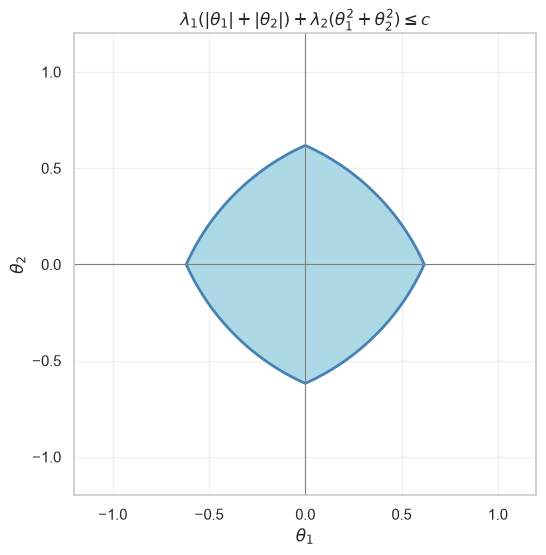

In [3]:
import numpy as np
import matplotlib.pyplot as plt

lambda_1 = 1.0
lambda_2 = 1.0
c = 1.0

theta = np.linspace(-1.2, 1.2, 800)
theta_1, theta_2 = np.meshgrid(theta, theta)

penalty = (
    lambda_1 * (np.abs(theta_1) + np.abs(theta_2))
    + lambda_2 * (theta_1**2 + theta_2**2)
)

fig, ax = plt.subplots(figsize=(6, 6))

ax.contourf(
    theta_1, theta_2, penalty,
    levels=[0, c],
    colors=["lightblue"],
)

ax.contour(
    theta_1, theta_2, penalty,
    levels=[c],
    colors=["steelblue"],
    linewidths=2,
)

ax.axhline(0, color="gray", linewidth=0.8)
ax.axvline(0, color="gray", linewidth=0.8)
ax.set_xlabel(r"$\theta_1$")
ax.set_ylabel(r"$\theta_2$")
ax.set_title(
    r"$\lambda_1(|\theta_1|+|\theta_2|)"
    r"+\lambda_2(\theta_1^2+\theta_2^2)\leq c$"
)
ax.set_aspect("equal")
ax.grid(alpha=0.3)

plt.show()

**2.** Выведите итерационную формулу пересчета коэффициентов модели с помощью формулы решения через проксимальный оператор.

Какой вы можете видеть эффект при изменении параметра регуляризации и в чем
его отличие от ридж и лассо-регрессии?

Так же, как в предыдущей части, разделим функцию потерь на гладкую часть и регуляризатор:

$$
\begin{aligned}
F_1(\theta) &= \|X\theta-Y\|_2^2, \\
R(\theta) &= \lambda_1\|\theta\|_1
+ \frac{\lambda_2}{2}\|\theta\|_2^2, \\
F(\theta) &= F_1(\theta)+R(\theta).
\end{aligned}
$$

Шаг проксимального градиентного метода:

$$
\begin{aligned}
\theta^{(t+\frac12)}
&= \theta^{(t)}-\eta\nabla F_1\bigl(\theta^{(t)}\bigr), \\
\theta^{(t+1)}
&= P_R\bigl(\theta^{(t+\frac12)}\bigr).
\end{aligned}
$$

Проксимальный оператор имеет вид:

$$
P_R(v)
=
\operatorname*{arg\,min}_{u}
\underbrace{
\left(
\frac{\|u-v\|_2^2}{2}
+\eta\lambda_1\|u\|_1
+\frac{\eta\lambda_2}{2}\|u\|_2^2
\right)
}_{g(u)}.
$$

Минимизацию можно выполнить отдельно по каждой координате:

$$
g(u)=\sum_i g_i(u_i),
\qquad
g_i(u_i)
=
\frac{(u_i-v_i)^2}{2}
+\eta\lambda_1|u_i|
+\frac{\eta\lambda_2}{2}u_i^2.
$$

При $u_i\ne 0$:

$$
g_i'(u_i)
=
\begin{cases}
(u_i-v_i)+\eta\lambda_2u_i+\eta\lambda_1,
& u_i>0, \\[4pt]
(u_i-v_i)+\eta\lambda_2u_i-\eta\lambda_1,
& u_i<0.
\end{cases}
$$

Приравнивая производную к нулю, получаем:

$$
\begin{aligned}
u_i>0
&\quad\Longrightarrow\quad
u_i=\frac{v_i-\eta\lambda_1}{1+\eta\lambda_2},
\qquad v_i>\eta\lambda_1, \\[6pt]
u_i<0
&\quad\Longrightarrow\quad
u_i=\frac{v_i+\eta\lambda_1}{1+\eta\lambda_2},
\qquad v_i<-\eta\lambda_1.
\end{aligned}
$$

В точке $u_i=0$ используем условие минимума через субдифференциал:

$$
0\in\partial g_i(0).
$$

Поскольку $\partial|u_i|\big|_{u_i=0}=[-1,1]$, имеем:

$$
\begin{aligned}
\partial g_i(0)
&= -v_i+\eta\lambda_1[-1,1], \\
0\in -v_i+\eta\lambda_1[-1,1]
&\quad\Longleftrightarrow\quad
-\eta\lambda_1\le v_i\le\eta\lambda_1.
\end{aligned}
$$

Таким образом,

$$
\bigl(P_R(v)\bigr)_i
=
\begin{cases}
\dfrac{v_i-\eta\lambda_1}{1+\eta\lambda_2},
& v_i>\eta\lambda_1, \\[8pt]
0,
& -\eta\lambda_1\le v_i\le\eta\lambda_1, \\[8pt]
\dfrac{v_i+\eta\lambda_1}{1+\eta\lambda_2},
& v_i<-\eta\lambda_1.
\end{cases}
$$

Введём оператор мягкого порогового преобразования, действующий покоординатно:

$$
\bigl(S_\tau(v)\bigr)_i
=
\operatorname{sign}(v_i)\max\{|v_i|-\tau,0\}.
$$

Тогда

$$
P_R(v)=\frac{S_{\eta\lambda_1}(v)}{1+\eta\lambda_2}.
$$

Итоговый шаг метода:

$$
\boxed{
\theta^{(t+1)}
=
\frac{
S_{\eta\lambda_1}\left(
\theta^{(t)}-\eta\nabla F_1\bigl(\theta^{(t)}\bigr)
\right)
}{
1+\eta\lambda_2
}
}
$$

Как то вроде нет уникальных эффектов. Просто комбинация обоих случаев.
Одновременно итеративно вычитается из результата (в пользу нуля) коэффциент $~\lambda_1$ и "сжимается" с коэффициентом $~(1 + \eta \lambda_2)$

**3.** Выпишите формулы для градиентного и стохастического спуска.

$$
\theta^{(t+1)}
=
\frac{
S_{\eta\lambda_1}\left(
\theta^{(t)}-\eta X^\top\left(X\theta^{(t)}-y\right)
\right)
}{
1+\eta\lambda_2
}
$$

$$
\theta^{(t+1)}
=
\frac{
S_{\eta\lambda_1}\left(
\theta^{(t)}-\eta X_I^\top\left(X_I\theta^{(t)}-y_I\right)
\right)
}{
1+\eta\lambda_2
}
$$

---
### <span style="display:inline-block;padding:6px 13px;border-radius:999px;background:linear-gradient(135deg,#D4470E 0%,#C7324E 55%,#B316B8 100%);color:#FFFFFF;font-size:16px;font-weight:700;line-height:1.2;">Задача 4</span>

**Введение**

Рассмотрим обезличенные [данные](https://www.kaggle.com/datasets/juice0lover/users-vs-bots-classification) о профилях пользователей ВК. Здесь собрана информация почти о 6 тыс. аккаунтах. Часть из них принадлежит реальным людям, а часть &mdash; боты. В этой задаче вы увидите, как регуляризация влияет на интерпретацию коэффициентов модели логистической регрессии.


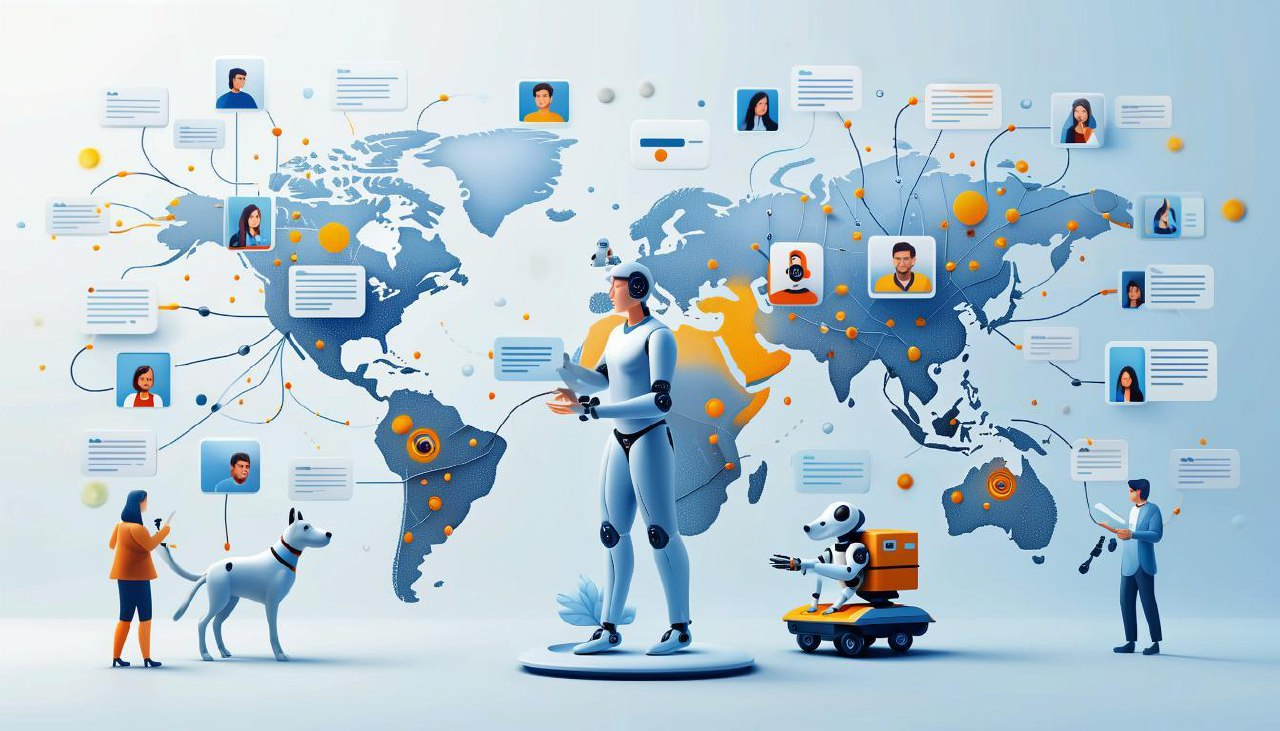

**Описание датасета**

Данные содержат 60 столбцов. Столбец `target` &mdash; метка целевого класса (бот/пользователь). Признаки можно условно разбить на несколько групп:

1. Числовые признаки:
    -   Метрики активности (среднее кол-во постов за неделю)
    -   Количество друзей/подписчиков
2. Категориальные признаки:
    -   Атрибуты профиля (установлен ли аватар, указан ли номер телефона)
    -   Город
    -   Настройки приватности (закрытый/открытый профиль)
    -   Различные бинарные флаги (можно ли писать в личные сообщения)

**1.** **Загрузка и подготовка данных**

Загрузите датасет, выведите его размер и описание числовых фичей при помощи метода `describe`. Отличается ли масштаб у числовых признаков?

In [4]:
path = kagglehub.dataset_download("juice0lover/users-vs-bots-classification")
dataset = pd.read_csv(f"{path}/bots_vs_users.csv")
dataset.head()

,has_domain,has_birth_date,has_photo,can_post_on_wall,can_send_message,has_website,gender,has_short_name,has_first_name,has_last_name,...,ads_ratio,avg_views,posting_frequency_days,phone_numbers_ratio,avg_text_uniqueness,city,has_occupation,occupation_type_university,occupation_type_work,has_personal_data
0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,...,NaN,NaN,NaN,NaN,NaN,Unknown,Unknown,Unknown,Unknown,Unknown
1,1.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,...,NaN,NaN,NaN,NaN,NaN,Unknown,Unknown,Unknown,Unknown,Unknown
2,1.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,...,NaN,NaN,NaN,NaN,NaN,Unknown,Unknown,Unknown,Unknown,Unknown
3,1.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,...,NaN,NaN,NaN,NaN,NaN,Unknown,Unknown,Unknown,Unknown,Unknown
4,1.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,...,NaN,NaN,NaN,NaN,NaN,Unknown,Unknown,Unknown,Unknown,Unknown


In [5]:
dataset.describe()

,target,posts_count,avg_likes,links_ratio,hashtags_ratio,avg_keywords,avg_text_length,attachments_ratio,avg_comments,reposts_ratio,ads_ratio,avg_views,posting_frequency_days,phone_numbers_ratio,avg_text_uniqueness
count,5874.000000,1391.000000,1391.000000,1391.000000,1391.000000,1391.000000,1391.000000,1391.000000,1391.000000,1391.000000,1391.000000,1391.000000,1391.000000,1391.000000,1391.000000
mean,0.500000,18.629044,19.552487,0.156463,0.143918,7.730661,544.752035,0.895945,0.610812,0.433638,0.002667,623.834788,66.330065,0.000568,0.668009
std,0.500043,4.231994,41.954881,0.202730,0.187085,11.278711,746.728130,0.170084,2.461709,0.397830,0.033136,1617.635460,154.970296,0.009545,0.229815
min,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,20.000000,0.400000,0.000000,0.000000,1.100000,86.600000,0.850000,0.000000,0.050000,0.000000,9.125000,1.980000,0.000000,0.580000
50%,0.500000,20.000000,7.600000,0.100000,0.050000,3.400000,267.800000,0.950000,0.000000,0.300000,0.000000,268.950000,30.950000,0.000000,0.710000
75%,1.000000,20.000000,26.075000,0.200000,0.200000,7.850000,616.850000,1.000000,0.200000,0.900000,0.000000,746.050000,89.480000,0.000000,0.830000
max,1.000000,20.000000,894.900000,1.000000,1.000000,61.600000,5841.250000,1.000000,64.050000,1.000000,0.950000,41415.700000,2866.590000,0.300000,1.000000


**Ответ:**

Отличается. Например масштаб avg_text_length ~500, а avg_comments ~3

Подсчитайте количество уникальных значений в столбце `city` и выведите 5 наиболее частых городов.

In [6]:
unique_count = dataset["city"].nunique(dropna=False)
distribution = dataset["city"].value_counts(dropna=False)
display(distribution.head(6))

city
Unknown             2780
Saint Petersburg    1549
Kostomuksha          405
Moscow               335
Petrozavodsk         103
Nizhny Novgorod       18
Name: count, dtype: int64

**Вывод:**

Больше всего пропусков. Следом самый популярный город Питер, потом... Костомукша?
Потом Москва.
Видимо большая часть Москвы прячется за метками Unknown. Откуда Костомукша я вообще не понимаю.

Само название города, который указан в профиле, нам не особо важно. **Замените** этот признак на простой бинарный флаг: указан/отсутствует.

In [7]:
# Сохраним неповторимый оригинал, будем работать с копией.
df = dataset.copy()

In [8]:
df["city"] = (df["city"] != "Unknown") * 1.0

In [10]:
# subscribers_count имеет неправильный тип.
df["subscribers_count"] = pd.to_numeric(df["subscribers_count"], errors="coerce")

Выделите целевую переменную и матрицу признаков, убрав из неё лишние столбцы (таргет и город):

In [11]:
y = df["target"]
df = df.drop(columns="target")

Посчитайте количество нулей и единиц таргете. Лучше всего представить ответ в виде графика с двумя столбцами, высота которых соответствует количеству объектов класса (см. например, [`sns.countplot`](https://seaborn.pydata.org/generated/seaborn.countplot.html)). Есть ли дисбаланс между классами?

<Axes: xlabel='target', ylabel='count'>

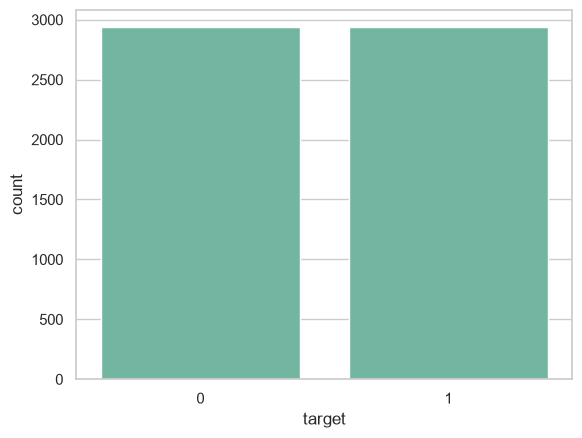

In [18]:
sns.countplot(x=y)

**Ответ:**

Дисбаланса нет.

Разделите данные на трейн и тест. Аналогичным образом выведите распределение таргета по классам для обеих выборок. Соотношение классов в обучающей и тестовой частях должно быть одинаковым.

In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    df, y,
    test_size=0.25,
    stratify=y,
    random_state=0,
)

Стандартизируйте **обучающую выборку**

In [20]:
scaler = StandardScaler()

numeric_cols = df.select_dtypes(include="number").columns
sorted(numeric_cols)

['ads_ratio',
 'attachments_ratio',
 'avg_comments',
 'avg_keywords',
 'avg_likes',
 'avg_text_length',
 'avg_text_uniqueness',
 'avg_views',
 'city',
 'hashtags_ratio',
 'links_ratio',
 'phone_numbers_ratio',
 'posting_frequency_days',
 'posts_count',
 'reposts_ratio',
 'subscribers_count']

In [21]:
X_train_scaled = X_train.copy()
X_train_scaled[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])
X_train_scaled

,has_domain,has_birth_date,has_photo,can_post_on_wall,can_send_message,has_website,gender,has_short_name,has_first_name,has_last_name,...,ads_ratio,avg_views,posting_frequency_days,phone_numbers_ratio,avg_text_uniqueness,city,has_occupation,occupation_type_university,occupation_type_work,has_personal_data
4137,1.0,1.0,1.0,0.0,1.0,0.0,1.0,1.0,1.0,1.0,...,-0.088341,-0.282272,-0.466217,-0.054001,0.038094,-1.074750,Unknown,Unknown,Unknown,1.0
1967,1.0,1.0,1.0,0.0,1.0,0.0,2.0,1.0,1.0,1.0,...,-0.088341,-0.363927,-0.472460,-0.054001,-0.396842,0.930449,Unknown,Unknown,Unknown,Unknown
3982,1.0,Unknown,1.0,0.0,1.0,0.0,1.0,1.0,1.0,1.0,...,-0.088341,-0.363927,-0.006470,-0.054001,1.125436,0.930449,1.0,1.0,0.0,1.0
2904,1.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,...,NaN,NaN,NaN,NaN,NaN,-1.074750,Unknown,Unknown,Unknown,Unknown
5273,1.0,Unknown,1.0,0.0,1.0,0.0,1.0,1.0,1.0,1.0,...,NaN,NaN,NaN,NaN,NaN,0.930449,1.0,1.0,0.0,Unknown
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2716,1.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,...,NaN,NaN,NaN,NaN,NaN,-1.074750,Unknown,Unknown,Unknown,Unknown
1116,1.0,Unknown,1.0,0.0,1.0,0.0,1.0,1.0,1.0,1.0,...,-0.088341,-0.359428,0.497683,-0.054001,-0.135880,0.930449,1.0,1.0,0.0,1.0
5737,1.0,1.0,1.0,0.0,1.0,0.0,1.0,1.0,1.0,1.0,...,-0.088341,0.370856,-0.263052,-0.054001,-0.092387,0.930449,1.0,0.0,1.0,1.0
5291,1.0,1.0,1.0,0.0,1.0,1.0,2.0,1.0,1.0,1.0,...,-0.088341,0.348779,0.345380,-0.054001,0.342550,0.930449,1.0,0.0,1.0,1.0


Согласно описанию на странице датасета, в данных присутствуют пропуски. Причём в числовых признаках они отмечены значением `NaN`, а в категориальных &mdash; строкой `"Unknown"`. Используя [`SimpleImputer`](https://scikit-learn.org/stable/modules/generated/sklearn.impute.SimpleImputer.html), заполните **числовые пропуски** средними значениями. Для каждого числового признака с пропусками создайте дополнительный признак-флаг, указывающий на наличие или отсутствие пропуска. Преобразуйте **только обучающую** выборку и убедитесь, что `NaN`-ов в ней действительно нет.

In [22]:
num_imputer = SimpleImputer(strategy="mean", add_indicator=True)
num_imputed = num_imputer.fit_transform(X_train_scaled[numeric_cols])
num_imputed_cols = num_imputer.get_feature_names_out(numeric_cols)

In [23]:
X_train_imputed = X_train_scaled.copy()
X_train_imputed[num_imputed_cols] = num_imputed

In [24]:
pd.set_option("display.max_rows", 100)
display(X_train_imputed.isna().sum())

has_domain                                 0
has_birth_date                             0
has_photo                                  0
can_post_on_wall                           0
can_send_message                           0
has_website                                0
gender                                     0
has_short_name                             0
has_first_name                             0
has_last_name                              0
access_to_closed_profile                   0
is_profile_closed                          0
has_nickname                               0
has_maiden_name                            0
has_mobile                                 0
all_posts_visible                          0
audio_available                            0
has_interests                              0
has_books                                  0
has_tv                                     0
has_quotes                                 0
has_about                                  0
has_games 

К категориальным признакам примените преобразование [OneHotEncoding](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html). При этом значения `"Unknown"` следует также распознавать как отдельную категорию.

In [25]:
cat_cols = X_train_imputed.select_dtypes(include=["object", "category", "string"]).columns
sorted(cat_cols)

['access_to_closed_profile',
 'all_posts_visible',
 'audio_available',
 'can_add_as_friend',
 'can_invite_to_group',
 'can_post_on_wall',
 'can_send_message',
 'gender',
 'has_about',
 'has_activities',
 'has_birth_date',
 'has_books',
 'has_career',
 'has_domain',
 'has_first_name',
 'has_games',
 'has_hometown',
 'has_interests',
 'has_last_name',
 'has_maiden_name',
 'has_military_service',
 'has_mobile',
 'has_movies',
 'has_music',
 'has_nickname',
 'has_occupation',
 'has_personal_data',
 'has_photo',
 'has_quotes',
 'has_relatives',
 'has_schools',
 'has_short_name',
 'has_status',
 'has_tv',
 'has_universities',
 'has_website',
 'is_blacklisted',
 'is_confirmed',
 'is_profile_closed',
 'is_verified',
 'marital_status',
 'occupation_type_university',
 'occupation_type_work']

In [26]:
cat_encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False,
).set_output(transform="pandas")

X_train_cat = cat_encoder.fit_transform(X_train_imputed[cat_cols])
X_train_encoded = pd.concat(
    [X_train_imputed.drop(columns=cat_cols), X_train_cat],
    axis=1,
)
X_train_encoded

,subscribers_count,posts_count,avg_likes,links_ratio,hashtags_ratio,avg_keywords,avg_text_length,attachments_ratio,avg_comments,reposts_ratio,...,has_occupation_1.0,has_occupation_Unknown,occupation_type_university_0.0,occupation_type_university_1.0,occupation_type_university_Unknown,occupation_type_work_0.0,occupation_type_work_1.0,occupation_type_work_Unknown,has_personal_data_1.0,has_personal_data_Unknown
4137,-3.787485e-01,3.292544e-01,-3.884085e-01,-7.602602e-01,-7.587002e-01,-2.723947e-01,-2.358042e-01,6.179330e-01,-3.231806e-01,-1.072424e+00,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0
1967,-4.678167e-01,3.292544e-01,-4.416067e-01,7.289597e-01,6.379929e-01,3.240701e+00,2.844002e+00,-2.191548e-01,-3.231806e-01,1.455585e+00,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0
3982,-6.056938e-02,3.292544e-01,-4.416067e-01,3.459196e+00,-7.587002e-01,-5.175981e-01,-5.988740e-01,-2.191548e-01,-3.231806e-01,-1.072424e+00,...,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0
2904,-3.309982e-17,-9.100547e-17,3.500211e-17,7.525453e-17,1.942617e-16,1.400084e-17,3.500211e-17,4.760286e-16,4.900295e-17,1.750105e-17,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0
5273,-1.751248e-01,-9.100547e-17,3.500211e-17,7.525453e-17,1.942617e-16,1.400084e-17,3.500211e-17,4.760286e-16,4.900295e-17,1.750105e-17,...,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2716,-3.309982e-17,-9.100547e-17,3.500211e-17,7.525453e-17,1.942617e-16,1.400084e-17,3.500211e-17,4.760286e-16,4.900295e-17,1.750105e-17,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0
1116,-4.606913e-01,3.292544e-01,-4.383497e-01,-2.638536e-01,-7.587002e-01,9.892881e-01,1.665905e+00,-2.191548e-01,-3.231806e-01,1.329185e+00,...,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0
5737,2.578043e+00,3.292544e-01,7.300512e-02,-5.120569e-01,-2.000230e-01,-4.953069e-01,-4.616832e-01,-4.981841e-01,-3.340294e-02,5.707820e-01,...,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
5291,7.536245e-02,3.292544e-01,-9.418945e-02,7.289597e-01,-4.793616e-01,-4.502430e-02,-1.076619e-01,3.389037e-01,7.197075e-02,-5.668219e-01,...,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0


Выше мы сделали некоторые шаги подготовки данных. Имеет ли значение порядок этих шагов или можно некоторым образом его поменять?

**Ответ:**

Scaler лучше оставить первым, иначе он поменяет результат OneHot.  
OneHot и SimpleImputer можно поменять, т.к. они независимо меняют действуют на разные колонки.

Хорошо ли обусловлена преобразованная матрица $X$? О чём это говорит?

In [27]:
condition_number = np.linalg.cond(X_train_encoded.to_numpy(dtype=float))
print(condition_number)

9.352631870979811e+33


**Ответ:**

Число очень большое, матрица плохо обусловлена. Среди строк есть линейная зависимость.

Для наглядности, выведите матрицу корреляций. Что означают элементы матрицы? А в нашем случае?

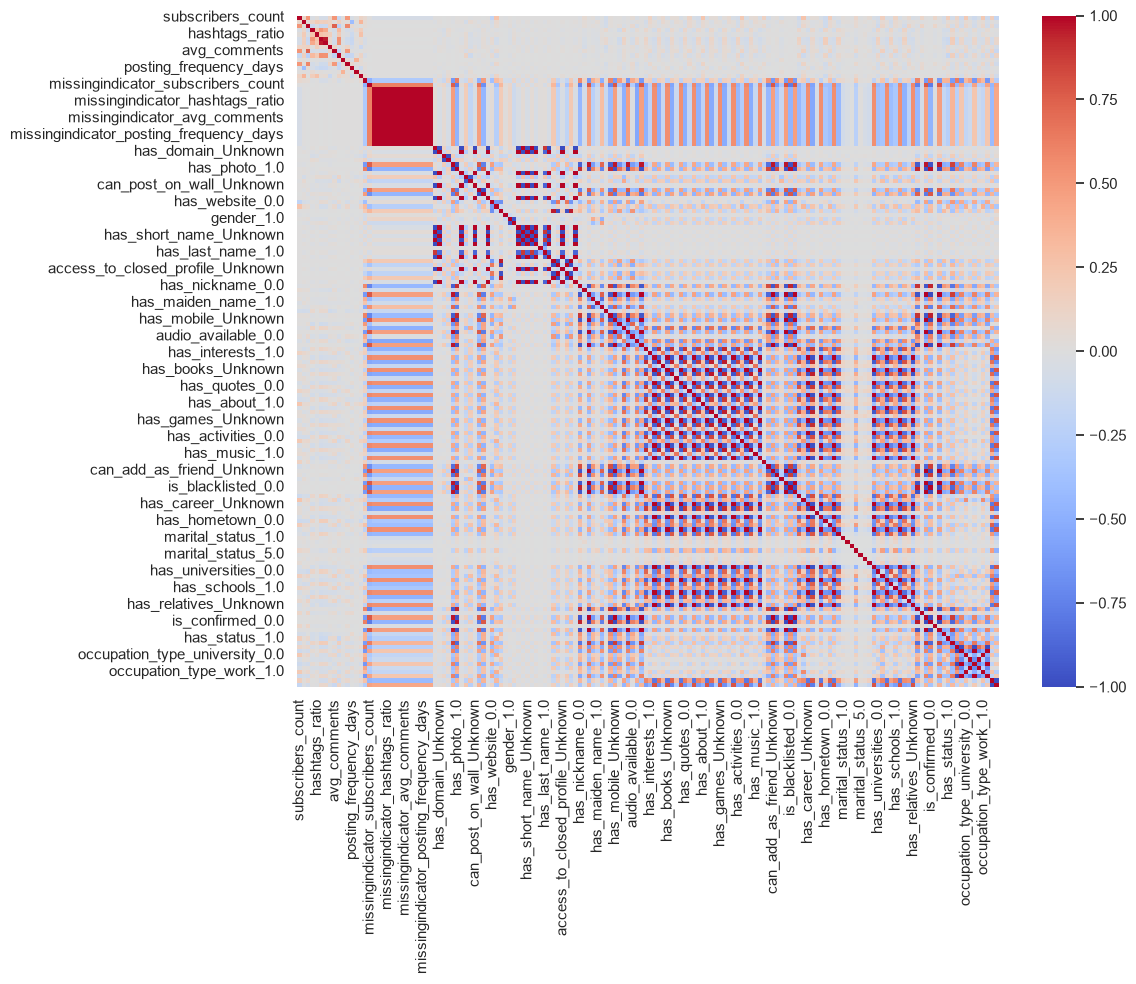

In [28]:
corr = X_train_encoded.corr(numeric_only=True)

plt.figure(figsize=(12, 10))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.tight_layout()
plt.show()

**Ответ:**

Целые кластера зависимых фичей. В целом матрица имеет множество скоррелированных фичей.

Мы сделали 3 преобразования над данными. Делать это вручную не вполне удобно и правильно. Гораздо лучше использовать пайплайн. Для этого зададим порядок выполнения преобразований так, как этого требует объект типа [`Pipeline`](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html):

In [29]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            make_pipeline(
                scaler,
                num_imputer,
            ),
            numeric_cols,
        ),
        (
            "categorical",
            make_pipeline(
                OneHotEncoder(handle_unknown="ignore", sparse_output=False),
            ),
            cat_cols,
        ),
    ],
).set_output(transform="pandas")

Теперь для создания пайплайна достаточно добавить саму модель как четвёртый шаг:


```
model = Pipeline(
    steps=preproc_steps + [
        ('estimator', <Инизиализированная модель>)
    ]
)
```
Такой подход является более надёжным и удобным.

In [30]:
# Проверим, что препроцессор правильно препроцессит.
preprocessor.fit(X_train)
check = preprocessor.transform(X_train)

print("Shapes:", check.shape, X_train_encoded.shape)
print("Columns match:", check.columns.equals(X_train_encoded.columns))
print("Row indexes match:", check.index.equals(X_train_encoded.index))
print("Missing values:", check.isna().sum().sum())

np.testing.assert_allclose(
    check.to_numpy(),
    X_train_encoded.to_numpy(),
)

Shapes: (4405, 160) (4405, 160)
Columns match: False
Row indexes match: True
Missing values: 0


**2.** **Модельки, модельки, модельки...**

**Логистическая регрессия без регуляризации**

Обучите классическую лог. регрессию без регуляризации и выведите точность ответа на трейне и тесте.

 
<br/>

<details style="box-sizing:border-box;max-width:100%;margin:0 0 18px;padding:8px 14px 10px;border:1px solid rgba(199,50,78,0.20);border-radius:10px;color:inherit;">

<summary style="cursor:pointer;color:inherit;font-size:13px;font-weight:750;text-decoration:underline;text-decoration-color:#C7324E;text-decoration-thickness:1.5px;text-underline-offset:3px;">Подсказка ✍️</summary>

Чему равен аргумент `penalty` по умолчанию?

</details>

In [31]:
model_no_reg = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(C=np.inf, max_iter=1000, intercept_scaling=1000000)),
])

model_no_reg.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](59,)","['has_domain','has_birth_date','has_photo',..., 'occupation_type_university','occupation_type_work','has_personal_data']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,59
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default o

In [208]:
print(f"Train accuracy: {model_no_reg.score(X_train, y_train):.3f}")
print(f"Test accuracy:  {model_no_reg.score(X_test, y_test):.3f}")

Train accuracy: 0.976
Test accuracy:  0.967


**Вывод:**

Ну даже так неплохо, 97%

**Логистическая регрессия с регуляризацией**

За что отвечает гиперпараметр `C` у класса `LogisticRegression`?

**Ответ:**

Это величина, обратная коэффициенту регуляризации $\lambda$

Вам необходимо исследовать зависимость от `C` следующих величин:
1. Accuracy на трейне
2. Accuracy на тесте
3. Коэффициенты модели

Чтобы не приходилось постоянно обучать модели при одних и тех же сетках `C`, предлагается написать функцию, которая будет принимать на вход вид штрафа `penalty`, границы диапазона `C`, и саму выборку. На каждой итерации вычисляйте все величины и сохраняйте в виде списков. Для мониторинга времени работы используйте функцию `tqdm`.

In [212]:
from sklearn.base import clone

def train_alpha_grid(
    log_C_bounds: Tuple[float, float],
    resolution: int,
    data: Dict[str, Any],
    preproc_steps: List[Tuple[str, Any]],
    penalty: str = "none",
    solver: str = "newton-cholesky",
    max_iter: int = 100,
) -> Tuple[List[np.ndarray], List[float], List[float]]:
    """Обучает модель LogisticRegression для разных значений параметра регуляризации C,
    сохраняет коэффициенты, вычисляет accuracy на обучающей и тестовой выборках.

    Args:
        log_C_bounds (Tuple[float, float]): кортеж с минимальным и максимальным значением log10(C) для сетки.
        resolution (int): число точек на сетке C.
        data (dict): словарь с обучающей и тестовой выборками (например, {'X_train': ..., 'y_train': ..., 'X_test': ..., 'y_test': ...}).
        preproc_steps (List[Tuple[str, Any]]): список шагов пайплайна.
        penalty (str): тип регуляризации ('l1', 'l2', 'elasticnet', 'none').
        solver (str): метод оптимизации параметров модели (см. аргумент `solver` у класса LogisticRegression).
        max_iter (int): обучение останавливается, если требуемая точность не достигнута за max_iter итераций.

    Returns:
        coefs_list (List[np.ndarray]): список массивов коэффициентов для каждого значения C.
        acc_train_list (List[float]): список accuracy на обучающей выборке для каждого значения C.
        acc_test_list (List[float]): список accuracy на тестовой выборке для каждого значения C.
    """

    l1_ratio_by_penalty = {
        "l1": 1.0,
        "l2": 0.0,
        "elasticnet": 0.5,
        "none": 1.0,
    }
    l1_ratio = l1_ratio_by_penalty[penalty]

    
    C_values = np.logspace(log_C_bounds[0], log_C_bounds[1], num=resolution)
    if penalty == "none":
        C_values = [np.inf]

    coefs_list: List[np.ndarray] = []
    acc_train_list: List[float] = []
    acc_test_list: List[float] = []

    for C in tqdm(C_values, desc="Training models"):
        model = LogisticRegression(
            C=C,
            l1_ratio=l1_ratio,
            solver=solver,
            max_iter=max_iter,
            intercept_scaling=1000000,
        )

        pipeline = Pipeline(
            [(name, clone(step)) for name, step in preproc_steps]
            + [("logistic_regression", model)]
        )
        pipeline.fit(data["X_train"], data["y_train"])

        fitted_model = pipeline.named_steps["logistic_regression"]
        coefs_list.append(
            np.column_stack((fitted_model.coef_, fitted_model.intercept_)).copy()
        )
        acc_train_list.append(
            pipeline.score(data["X_train"], data["y_train"])
        )
        acc_test_list.append(
            pipeline.score(data["X_test"], data["y_test"])
        )

    return coefs_list, acc_train_list, acc_test_list

Проведите эксперимент для 3-х разных моделей логистической регрессии с различными типами регуляризации:
1.  $L_1$-регуляризация
2.  $L_2$-регуляризация
3.  Комбинированная регуляризация с параметром `l1_ratio=0.5`.

>*Рекомендации*
>*   Подберите диапазоны значений для гиперпараметра `C`. Не берите слишком узкие, чтобы видеть на графике всю картину. Для слишком широких границ придётся брать больше точек.
>*   Вам не нужна очень частая сетка гиперпараметра `C`. При отладке кода можно вообще использовать сетку из 2-3 значений.
>*   Вы можете столкнуться с различными ошибками и `warning`-ами (например, неверный `solver`, отсутствие сходимости,  и т.д.). Постарайтесь настроить гиперпараметры модели таким образом, чтобы ошибки исчезли, а количество предупреждений было минимальным.

In [199]:
penalties = ["l1", "l2", "elasticnet", "none"]
log_C_bounds = (-4, 4)
resolution = 12
C_values = np.logspace(*log_C_bounds, num=resolution)

data = {
    "X_train": X_train,
    "y_train": y_train,
    "X_test": X_test,
    "y_test": y_test,
}
preproc_steps = [("preprocessor", preprocessor)]

results = {}

for penalty in penalties:
    results[penalty] = train_alpha_grid(
        log_C_bounds=log_C_bounds,
        resolution=resolution,
        data=data,
        solver="saga",
        preproc_steps=preproc_steps,
        penalty=penalty,
        max_iter=1000,
    )

Training models:  42%|█████████████████████████████████▊                                               | 5/12 [00:03<00:05,  1.24it/s]/nix/store/ppddjmh1vzk9snl6jklzmfw1v1gm24aa-python3.14-scikit-learn-1.9.0/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
Training models:  50%|████████████████████████████████████████▌                                        | 6/12 [00:06<00:08,  1.45s/it]/nix/store/ppddjmh1vzk9snl6jklzmfw1v1gm24aa-python3.14-scikit-learn-1.9.0/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
Training models:  58%|███████████████████████████████████████████████▎                                 | 7/12 [00:09<00:09,  1.96s/it]/nix/store/ppddjmh1vzk9snl6jklzmfw1v1gm24aa-python3.14-scikit-learn-1.9.0/lib/python3.14/site-packages/sklearn/linear_mode

Выберите 8-15 признаков на своё усмотрение либо случайным образом. Нарисуйте треки соответствующих коэффициентов моделей в зависимости от `C`. Свободный коэффициент тоже стоит добавить на графики. Легенду можно сделать общую, если все графики помещаются на экране. Отразите в ней наименования признаков для соответствующих коэффициентов. Сделать красиво могут помочь заметки [отсюда](https://stackoverflow.com/questions/4700614/how-to-put-the-legend-outside-the-plot).

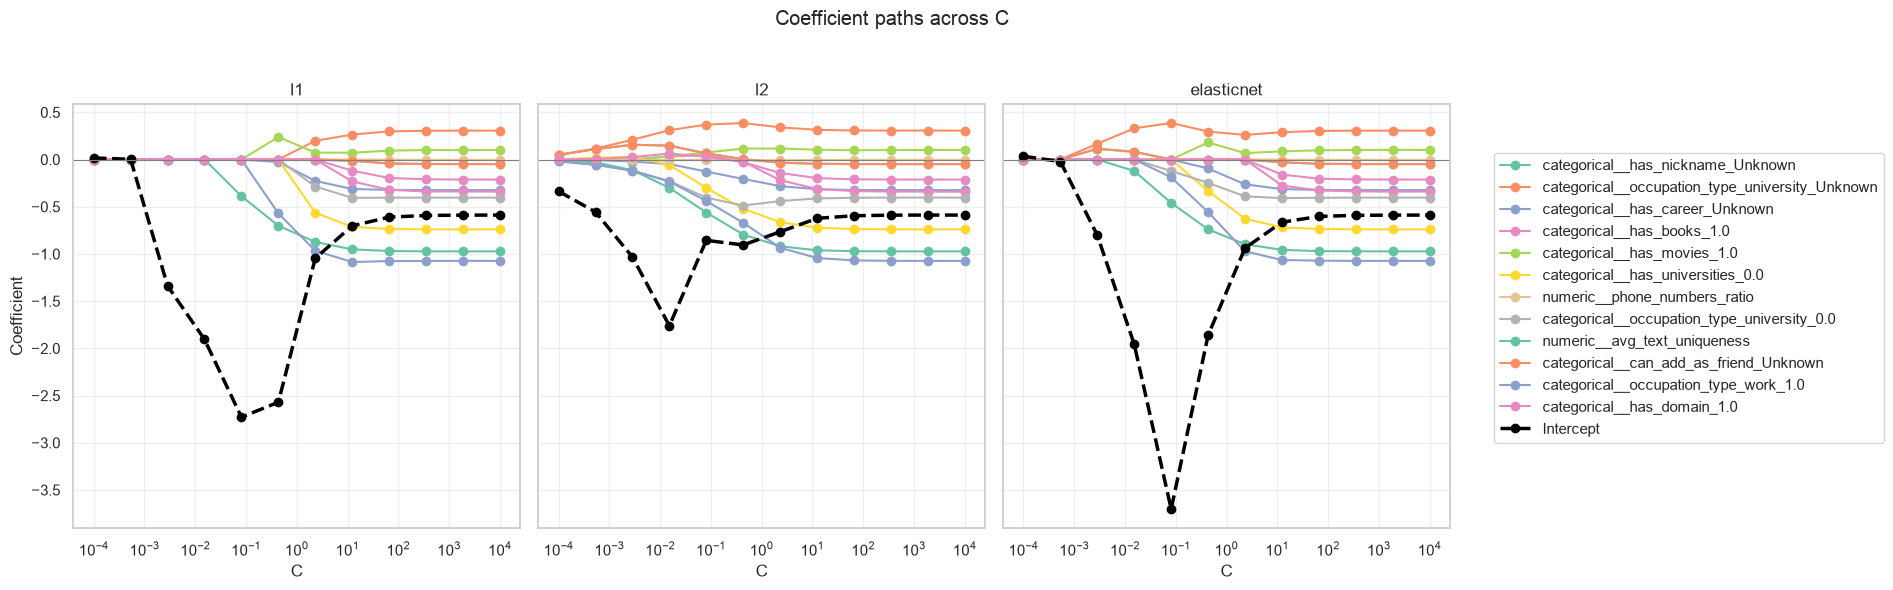

In [200]:
C_values = np.logspace(*log_C_bounds, num=resolution)
feature_names = preprocessor.get_feature_names_out()

rng = np.random.default_rng(42)
selected_idx = rng.choice(
    len(feature_names),
    size=min(12, len(feature_names)),
    replace=False,
)

fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True)

for ax, penalty in zip(axes, penalties):
    coefs, _, _ = results[penalty]

    # For binary classification, row 0 contains the model coefficients.
    coef_path = np.vstack([coef[0] for coef in coefs])

    for idx in selected_idx:
        ax.plot(
            C_values,
            coef_path[:, idx],
            marker="o",
            label=feature_names[idx],
        )

    ax.plot(
        C_values,
        coef_path[:, -1],
        marker="o",
        linestyle="--",
        linewidth=2.5,
        color="black",
        label="Intercept",
    )

    ax.axhline(0, color="gray", linewidth=0.8)
    ax.set_xscale("log")
    ax.set_title(penalty)
    ax.set_xlabel("C")
    ax.grid(True, alpha=0.3)

axes[0].set_ylabel("Coefficient")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="center left", bbox_to_anchor=(0.83, 0.5))
fig.suptitle("Coefficient paths across C")
fig.tight_layout(rect=(0, 0, 0.82, 0.95))
plt.show()

**Вывод:**

sklearn по умолчанию применяет регуляризацию к intercept, наверное это стоит отключить (что я и сделал, но почему то это не особо помогло...).  
Остальные коэффициенты ведут себя согласно теории. При C=0 ($\lambda=\infty$), коэффициенты равны 0.  
При увеличении C они начинают иметь ненулевые значения.  
При этом в случае $l1$ они "отлипают" от 0 скачком, а в случае $l2$ -- плавно меняются.  
В elasticnet происходит что-то среднее. 

Нарисуйте зависимости точности предсказания от `C` на обучающей и тестовой выборках. Скомпонуйте всё на 2-3 графиках. Горизонтальными линиями отметьте точность модели без регуляризации на тесте.

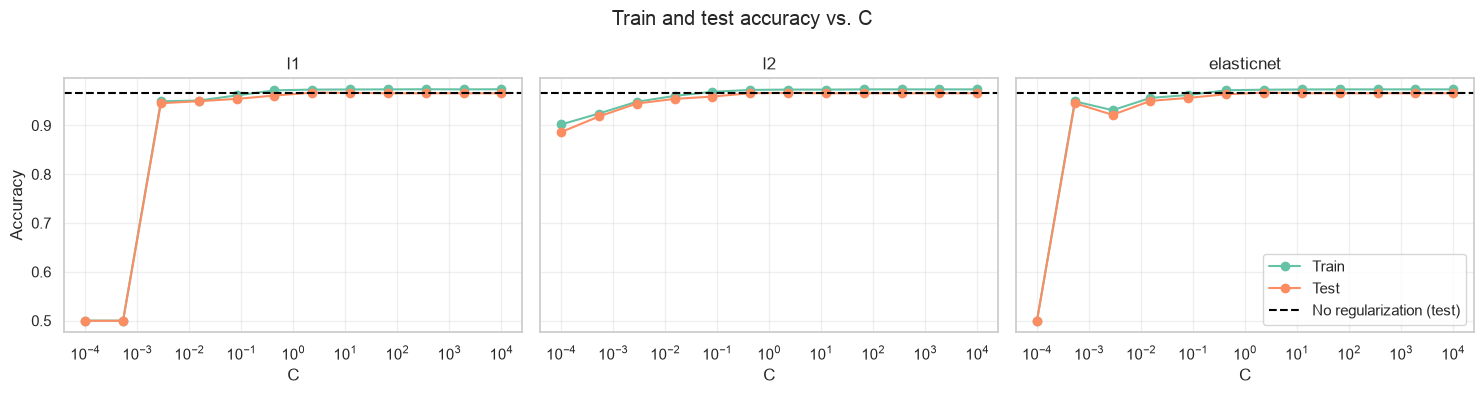

In [201]:
C_values = np.logspace(*log_C_bounds, num=resolution)
baseline_test_accuracy = results["none"][2][0]

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

for ax, penalty in zip(axes, ["l1", "l2", "elasticnet"]):
    _, train_accuracy, test_accuracy = results[penalty]

    ax.plot(C_values, train_accuracy, marker="o", label="Train")
    ax.plot(C_values, test_accuracy, marker="o", label="Test")
    ax.axhline(
        baseline_test_accuracy,
        color="black",
        linestyle="--",
        label="No regularization (test)",
    )

    ax.set_xscale("log")
    ax.set_title(penalty)
    ax.set_xlabel("C")
    ax.grid(True, alpha=0.3)

axes[0].set_ylabel("Accuracy")
axes[-1].legend()
fig.suptitle("Train and test accuracy vs. C")
fig.tight_layout()
plt.show()

Сделайте вывод. Есть ли польза от регуляризации с точки зрения метрики?

**Вывод:**

С точки зрения метрики как будто пользы не особо

**3.** **Число обусловленности**

Исследуйте зависимость числа обусловленности от параметра `C` для $L_2$-регуляризации. Постройте соответствующий график.

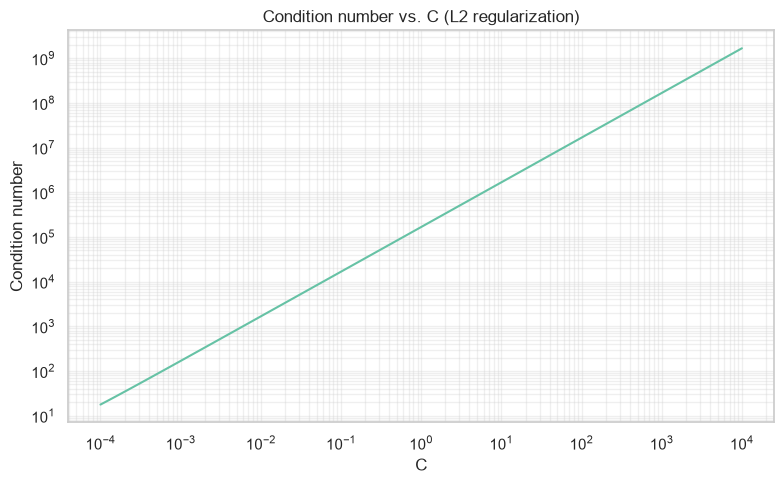

In [206]:
X = np.asarray(X_train_encoded, dtype=float)

gram = X.T @ X
identity = np.eye(X.shape[1])
C_values = np.logspace(-4, 4, 100)

condition_numbers = [
    np.linalg.cond(gram + identity / C)
    for C in C_values
]

plt.figure(figsize=(8, 5))
plt.plot(C_values, condition_numbers)
plt.xscale("log")
plt.yscale("log")
plt.xlabel("C")
plt.ylabel("Condition number")
plt.title("Condition number vs. C (L2 regularization)")
plt.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()

Сделайте вывод. О чём свидетельствует полученная зависимость?

**Вывод:**

Зависимость оказывается линейной (этот вывод сделан по графику без лог шкалы).
То есть чем ниже C (и выше коэффициент регуляризации), тем число обусловленности ближе к 1 и матрица становится "более обратимой". 

**4.** **Разброс коэффициентов**

Рассмотрите **2 модели:** логистическая регрессия с регуляризацией по-умолчанию и с `penalty=None`. Каждую модель обучите 500 раз при различных разбиениях на обучающую и тестовую выборки. Сохраните коэффициенты для выбранных ранее признаков. Подсчитайте усреднённую метрику качества и визуализируйте распределение каждого коэффициента. Не забудьте про пайплайн.

> Визуализацию предлагается сделать виде сетки графиков. На каждом изобразите **ядерные оценки плотности** для соответствующего коэффициента обеих моделей.
>
> Также напоминаем про удобство использования [логарифмической шкалы](https://matplotlib.org/stable/api/scale_api.html#builtin-scales).

In [210]:
model_no_reg = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(C=np.inf, max_iter=1000, intercept_scaling=1000000)),
])
model_reg = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000, intercept_scaling=1000000)),
])
models = {
    "No regularization": model_no_reg,
    "L2 regularization": model_reg,
}

In [221]:
n_splits = 500

coefs_by_model = {name: [] for name in models}
scores_by_model = {name: [] for name in models}

for split_id in tqdm(range(n_splits), desc="Repeated train/test splits"):
    X_train, X_test, y_train, y_test = train_test_split(
        df,
        y,
        test_size=0.2,
        random_state=split_id,
        stratify=y,
    )

    for name, base_pipeline in models.items():
        fitted = clone(base_pipeline)
        fitted.fit(X_train, y_train)

        scores_by_model[name].append(fitted.score(X_test, y_test))

        fitted_preprocessor = fitted.named_steps["preprocessor"]
        fitted_feature_names = fitted_preprocessor.get_feature_names_out()
        classifier = fitted.named_steps["model"]

        # This uses the first coefficient row, as appropriate for binary classification.
        coef_series = pd.Series(
            classifier.coef_[0],
            index=fitted_feature_names,
        )
        coef_series["__intercept__"] = classifier.intercept_[0]
        coefs_by_model[name].append(coef_series)

Repeated train/test splits: 100%|███████████████████████████████████████████████████████████████████| 500/500 [01:32<00:00,  5.43it/s]


In [222]:
for name, scores in scores_by_model.items():
    print(f"{name}: mean test accuracy = {np.mean(scores):.4f}")

No regularization: mean test accuracy = 0.9673
L2 regularization: mean test accuracy = 0.9683


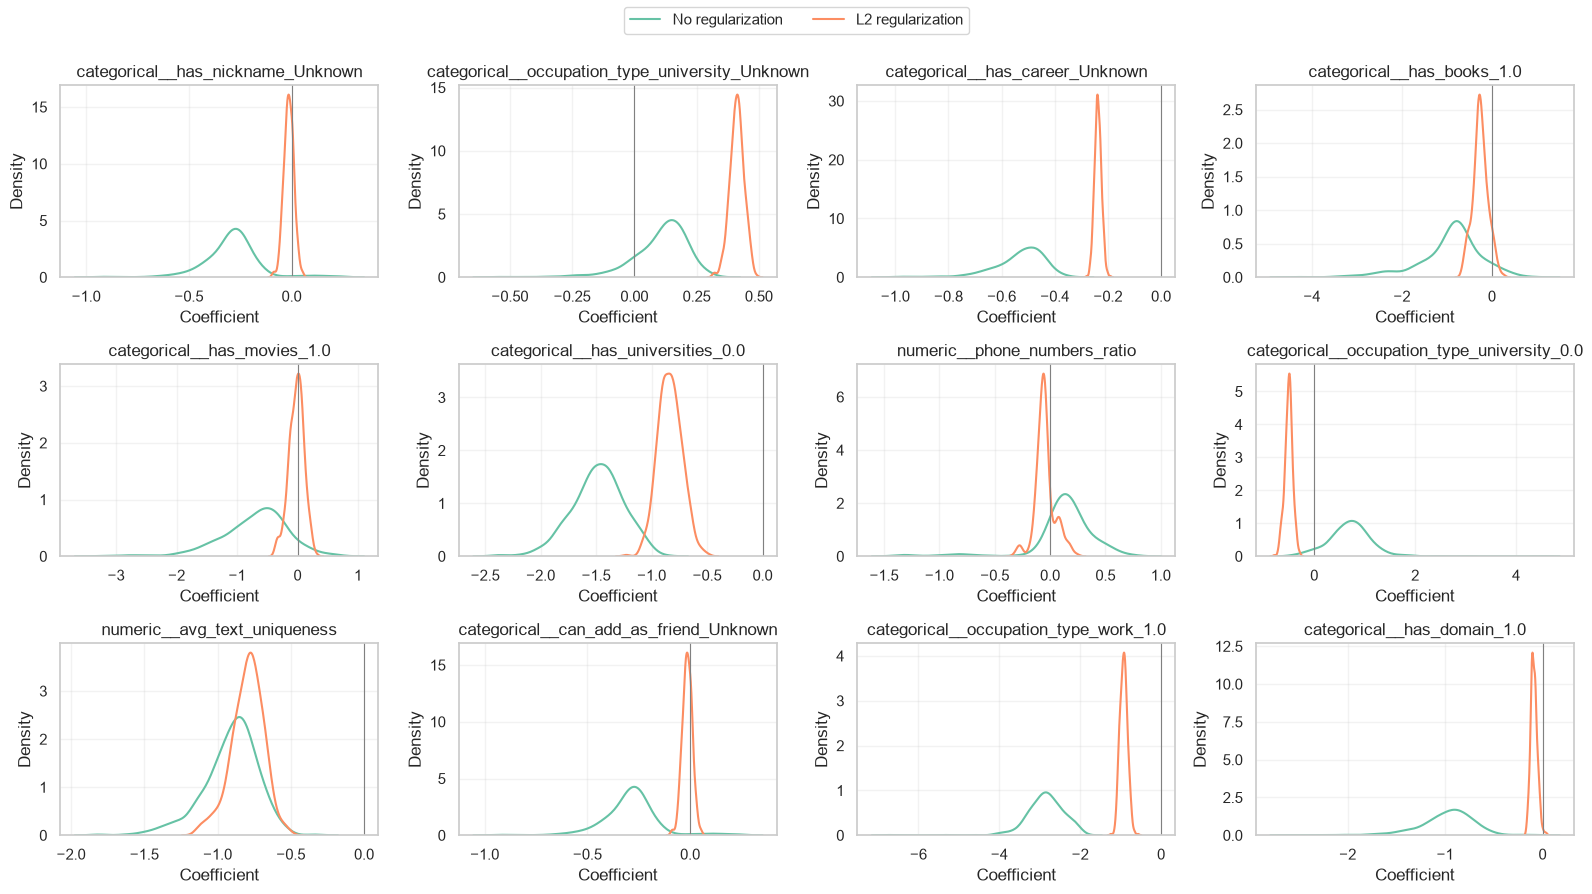

In [223]:
selected_feature_names = np.asarray(feature_names)[selected_idx]
coef_frames = {
    name: pd.DataFrame(rows)
    for name, rows in coefs_by_model.items()
}

n_cols = 4
n_rows = int(np.ceil(len(selected_feature_names) / n_cols))
fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(4 * n_cols, 3 * n_rows),
    squeeze=False,
)
axes = axes.ravel()

for i, feature in enumerate(selected_feature_names):
    ax = axes[i]

    for model_name, coef_frame in coef_frames.items():
        if feature in coef_frame.columns:
            sns.kdeplot(
                x=coef_frame[feature].fillna(0),
                ax=ax,
                label=model_name,
                warn_singular=False,
            )

    ax.axvline(0, color="gray", linewidth=0.8)
    ax.set_title(feature)
    ax.set_xlabel("Coefficient")
    ax.grid(True, alpha=0.25)

for ax in axes[len(selected_feature_names):]:
    ax.set_visible(False)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=len(models))
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

Какой модели вы больше доверитесь при интерпретации коэффициентов? Почему разработчики sklearn по-умолчанию добавили в логистическую регрессию небольшую $L_2$-регуляризацию? В чём заключается её польза? Порассуждайте над этими вопросами и попробуйте написать интерпретацию выведенных коэффициентов.

Модель с регуляризацией обладает существенно меньшей дисперсией по признакам при обучении. Для модели без регуляризации мы фактически играем в рулетку -- какой набор из этих распределений попадется.  
И каждый раз будет разный. Попытка интерпретировать по нему коэффициенты достаточно бессмысленна, т.к. мы будем пытаться сказать что-то умное базируясь на по сути случайном ответе.  
В случае с регуляризацией разброс заметно меньше и обладает таким образом большей надежностью. Мы можем быть уверены, что как бы данные не были разбиты на train и test, результат будет примерно похожий.  
Соответственно и sklearn по этой причине добавляет небольшую регуляризацию.

**Вывод**

1. Нормируем данные.
2. Категории переводим в числа с помощью onehot.
3. В числовых признаках заполняем пропуски и помечаем что пропуск был в отдельном признаке.
4. Используем регуляризацию.

<div style="box-sizing:border-box;max-width:100%;margin-top:42px;padding:18px 0 4px;border-top:1px solid rgba(127, 127, 127, 0.28);color:inherit;font-size:0.9em;line-height:1.5;"><img src="https://thetahat.ru/images/logo_thetahat.png" alt="ThetaHat" style="display:block!important;width:34px!important;max-width:34px!important;height:auto!important;margin:0 0 9px 0!important;padding:0!important;">© 2026 команда <a href="https://thetahat.ru/" style="color:inherit;font-weight:750;text-decoration:underline;text-decoration-color:#F13A3F;text-underline-offset:3px;">ThetaHat</a> для курса ML-1 ШАД</div>